---
numbering: false
---

# Basic SAR Access and Analysis

In this recipe, we will be looking at a very basic example of accessing Synthetic Aperture Radar (SAR) data from the Sentinel-1 satellite constellation.

This aims to be a quick peek into accessing actively sensed radar data rather than the passive optical imagery you will become used to in this course. This comes with some heavy caveats:

 - **This is *not* a SAR or radar processing course**. I will not be explaining components of SAR processing in detail, but [direct you to useful resources at the bottom of the page](#visualising-sar-data).
 - We are going to be using pre-processed Ground Range Detected (GRD) data produced for the Microsoft Planetary Computer, meaning we are only looking at the amplitude/backscatter intensity, not the phase: so no Interferometric SAR (InSAR), deformation mapping, or phase unwrapping.
 - SAR data requires careful handling due to complexities such as geomoetry distortions (layover/shadow), speckle noise, and dB conversions: treat this as a qualitative overview to primarily outline basic data access and handling.

**I probably wouldn't recommend choosing SAR data for your final course project**, unless you are confident in using this data from prior interactions. However, you might be inspired to look further into SAR analaysis opportunities for your final MSc Dissertation, particularly approaches that can take advantage of pre-processed GRD/RTC data from either the Microsoft Planetary Computer or Google Earth Engine.

In [10]:
import pystac_client
import planetary_computer
import odc.stac

import geopandas as gpd
import rioxarray as rxr
import numpy as np

import matplotlib.pyplot as plt

from shapely import box
from pystac import ItemCollection

## Searching and downloading SAR Data

Microsoft Planetary Computer provides both **Ground Range Detected (GRD)** and **Radiometrically Terrain Corrected (RTC)** data, [as described in the dataset overview](https://planetarycomputer.microsoft.com/dataset/group/sentinel-1). 

Sentinel-1 data is collected from a sideways-looking active radar. Raw return data is referred to as a a **Single Look Complex (SLC)** product. GRD is a standard, baseline Sentinel-1/SAR product, which maps the sideways looking radar ("slant range") onto a flat, smooth model of Earth ("ground range"). This ignores topography, and can result in slopes that face the raddar looking unnaturally bright and squished (layover), whilst slopes facing away are hidden in darkness (shadow). For flat regions and quick, lightweight, explorations, this is fine. An RTC product uses a DEM to 'flatten' this 3D landscape and remove or mitigate some of these topography-induced artefacts. It is better for serious quantitative analysis, time-series monitoring, and mountainous terrain. Microsoft's RTC product is a useful first pass at this, although serious SAR users may choose to use their own RTC processing chains that make use of local, rather than global, DEMs. 

We wil choose RTC for now:

In [50]:
# Provide a name for our area of interest (AOI)
aoi_name = "bristol"

# Provide the bounding box coordinates for the AOI in the format [min_lon, min_lat, max_lon, max_lat]
bbox = [-2.76, 51.38,-2.43,51.53]

# Provide the date range for the search in the format "YYYY-MM-DD/YYYY-MM-DD"
daterange = "2026-06-01/2026-08-31"  # summer 2026

# Filter only to scenes where fractional coverage of bounding box exceeds desired threshold
aoi_fraction_threshold = .7  # 70% minimum

# Provide a 'collection' from the Microsoft Planetary Computer STAC API to search for imagery. 
collection = "sentinel-1-rtc"  # Sentinel-1 RTC data. See also: sentinel-1-grd for GRD data.

Turn our bbox list into a `GeoPandas` dataframe to sanity check we have the correct region:

In [39]:
aoi = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

# aoi.explore()

Connect the Microsoft Planetary Computer.

In [38]:
# Connect to the MPC
stac_url = "https://planetarycomputer.microsoft.com/api/stac/v1"

catalog = pystac_client.Client.open(
    stac_url,
    modifier=planetary_computer.sign_inplace,  # only needed for MPC

    )

Search for the dataset according to our search parameters.

In [44]:
# Search for Sentinel-1 data
search = catalog.search(
    collections=[collection],
    bbox=bbox,
    datetime=daterange,
    query={
        "sar:instrument_mode": {"eq": "IW"},  # default to intermediate wide swath mode, which is suitable for most common EO applications (cf: EW, SM, WV modes)
    }
)

# Convert the search result object into a list of `pystac.Item` objects
items = search.item_collection()
print(f"Found {len(items)} matching scene(s).")

Found 58 matching scene(s).


The next cell is a custom script that filters out satellite scenes that only clip the area of interest by a small fraction. The minimum fraction you would like is set by `bbox_fraction_threshold` above (defaults to `0.7`, i.e. 70%).

In [45]:
# convert aoi to a geopandas dataframe
aoi_gdf = gpd.GeoDataFrame(geometry=[box(*bbox)], crs="EPSG:4326")

# convert search results to a geopandas dataframe
search_gdf = gpd.GeoDataFrame.from_features(items.to_dict(), crs="EPSG:4326")

# convert both to an equal area projection (EPSG:8857) so we can work in metres
aoi_gdf = aoi_gdf.to_crs(8857)
search_gdf = search_gdf.to_crs(8857)

# clip search gdf to aoi gdf
search_gdf = search_gdf.clip(aoi_gdf)

# Calculate the fraction of the AOI covered by each scene
search_gdf = search_gdf.sort_index()
search_gdf["frac"] = search_gdf.area / aoi_gdf.area.values[0]

# Include a boolean column indicating whether the scene exceeds the AOI fraction threshold
search_gdf["exceed_frac"] = np.where(search_gdf["frac"].values >= aoi_fraction_threshold, True, False)

# Reconstruct the ItemCollection with only the items that exceed the AOI fraction threshold
items_list = []
for i, exceed_frac in zip(items, search_gdf.exceed_frac.values):
    if exceed_frac == True:
        items_list.append(i)

items = ItemCollection(items=items_list)
print(f"Afer AOI filtering, returns {len(items)} Items")

Afer AOI filtering, returns 29 Items


Even after filtering, this is a lot of items! For analaysis, you may wish to include some `query` filters that cut down the search space further.

For instance, filtering to `"sat:orbit_state"` to either `"ascending"` or `"descending"` will limit returns to only ascending or descending orbital passes, and help all scenes to share the same illumination angle. Similarly, after finding a single good scene you may wish to filter `"sat:relative_orbit"` to ensure that every scene is captured along the same orbital path. 


```python
    query={
            "sat:orbit_state": {"eq": "ascending"},
            "sat:relative_orbit": {"eq": 15},  # Pick one specific track number
        },
```

Together, these help to ensure that any SAR data in the times-series you inspect is captured from the same angle and direction, ensuring consistency between images and aiding comparison.

Let's pick the first item and view the properties. Note that things are a little more complex than for optical data.

In [46]:
item = items[0]

item.properties

{'datetime': '2026-08-30T17:57:03.428066Z',
 'platform': 'sentinel-1c',
 's1:shape': [28999, 21423],
 'proj:bbox': [409800.0, 5542960.0, 699790.0, 5757190.0],
 'proj:shape': [21423, 28999],
 'end_datetime': '2026-08-30T17:57:15.927389Z',
 'constellation': 'Sentinel-1',
 'proj:centroid': {'lat': 50.99096, 'lon': -2.21585},
 's1:resolution': 'high',
 'proj:transform': [10.0, 0.0, 409800.0, 0.0, -10.0, 5757190.0, 0.0, 0.0, 1.0],
 's1:datatake_id': '75104',
 'start_datetime': '2026-08-30T17:56:50.928743Z',
 's1:orbit_source': 'PREORB',
 's1:slice_number': '12',
 's1:total_slices': '23',
 'sar:looks_range': 5,
 'sat:orbit_state': 'ascending',
 'sar:product_type': 'GRD',
 'sar:looks_azimuth': 1,
 'sar:polarizations': ['VV', 'VH'],
 'sar:frequency_band': 'C',
 'sat:absolute_orbit': 9228,
 'sat:relative_orbit': 30,
 's1:processing_level': '1',
 'sar:instrument_mode': 'IW',
 'sar:center_frequency': 5.405,
 'sar:resolution_range': 20,
 's1:product_identifier': 'S1C_IW_GRDH_1SDV_20260830T175650_2

We can still use `odc-stac` to download a chunk of data:

In [47]:
# Load requested bands directly into an xarray.Dataset using odc-stac
ds = odc.stac.load(
    [item],
    # bands=bands,
    bbox=bbox,
    # crs="EPSG:XXXX",  # Uncomment if you want a different projection: by default, will use the native CRS
    # resolution=100, # Uncomment if you want a different resolution: by default, will use the native resolution of the imagery
).squeeze()

# xarray is 'lazy' by default, meaning it doesn't load the data into memory until you explicitly ask for it.
# The `.compute()` method forces the data to be loaded into memory, which can take some time depending on the size of the dataset.
ds.compute()

<xarray.Dataset> Size: 31MB
Dimensions:      (y: 1681, x: 2303)
Coordinates:
  * y            (y) float64 13kB 5.709e+06 5.709e+06 ... 5.692e+06 5.692e+06
  * x            (x) float64 18kB 5.166e+05 5.167e+05 ... 5.397e+05 5.397e+05
    spatial_ref  int32 4B 32630
    time         datetime64[ns] 8B 2026-08-30T17:57:03.428066
Data variables:
    vh           (y, x) float32 15MB 0.004898 0.005206 ... 0.01029 0.006907
    vv           (y, x) float32 15MB 0.01703 0.01487 0.01584 ... 0.05334 0.04682

We have two bands: `vv` and `vh`. Depending on where you are in the world and what products you have selected to download, you may have different combinations of `vv`, `hh`, `vh`, and `hv`. In brief:

 - **VV / HH (Single polarisation)**: Sent and received in the same plane (sensitive to surface roughness and soil moisture).
 - **VH / HV (Cross-polarisation)**: Sent in one plane, received in another (sensitive to volume scattering, like dense vegetation or urban structures).

## Visualising SAR Data

Raw Sentinel-1 RTC pixels represent radar backscatter intensity (gamma-naught, $\gamma^0$). They measure the fraction of the microwave energy sent by the satellite that bounces off the Earth's surface and returns to the antenna.

Low values (near 0) indicate surfaces like calm water or flat asphalt that bounce radar away like a mirror. High values (1+): indicate rough surfaces, dense vegetation, or urban structures that scatter energy back in all directions. 

It is useful to convert this data into decibels (dB), which is a log scale. This is because radar backscatter has an enormous dynamic range — it can span several orders of magnitude, from 0.0001 over water to 10+ over e.g. a metal building. If you plot raw linear values, everything will look either pitch black or blindingly white. Converting to decibels using a base-10 logarithm:

$$\text{dB} = 10 \times \log_{10}(\text{intensity})$$

This compresses that massive range into a neat, manageable window, bringing out subtle variations in soil, water, and crops so our eyes (and screens) can actually see them.

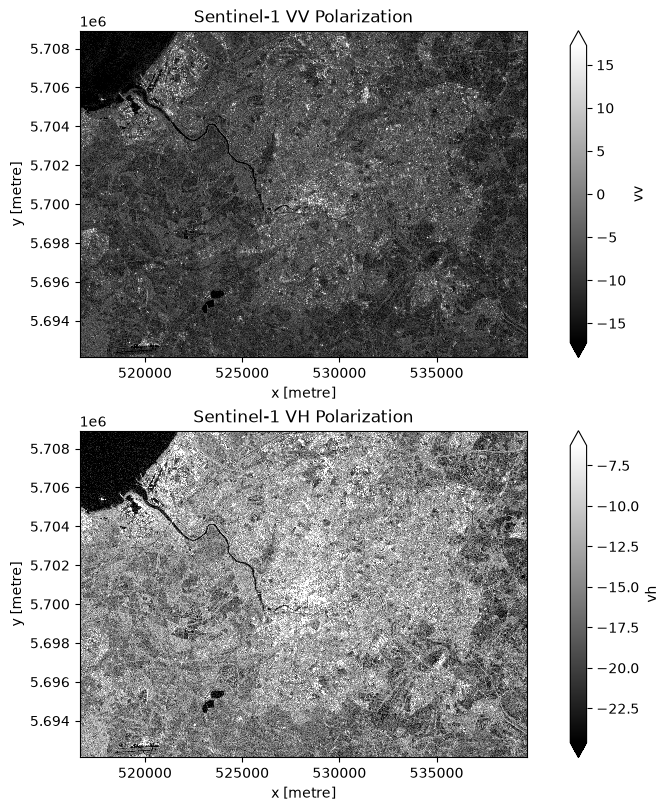

In [52]:
# convert to dB scale for better visualization
vv_log = 10 * np.log10(ds.vv)
vh_log = 10 * np.log10(ds.vh)

fig, axes = plt.subplots(nrows=2, layout="constrained", figsize=(10, 8))

ax = axes[0]
vv_log.plot.imshow(ax=ax, cmap="gray", robust=True)
ax.set_title("Sentinel-1 VV Polarization")
ax.set_aspect('equal')

ax = axes[1]
vh_log.plot.imshow(ax=ax, cmap="gray", robust=True)
ax.set_title("Sentinel-1 VH Polarization")
ax.set_aspect('equal')

## (Very) Basic Analysis

One low-hanging use of SAR data is to classify water. Water acts like a smooth specular surface; radar pulses bounce away from the sensor, resulting in very low backscatter (appearing very dark in VV/VH). Values of roughly <22 dB for VH and ≤15 dB for VV are often chosen as reasonable (but not universal) thresholds. Histogram inspection may help to improve this.

Let's filter to these common thresholds and see what we get:

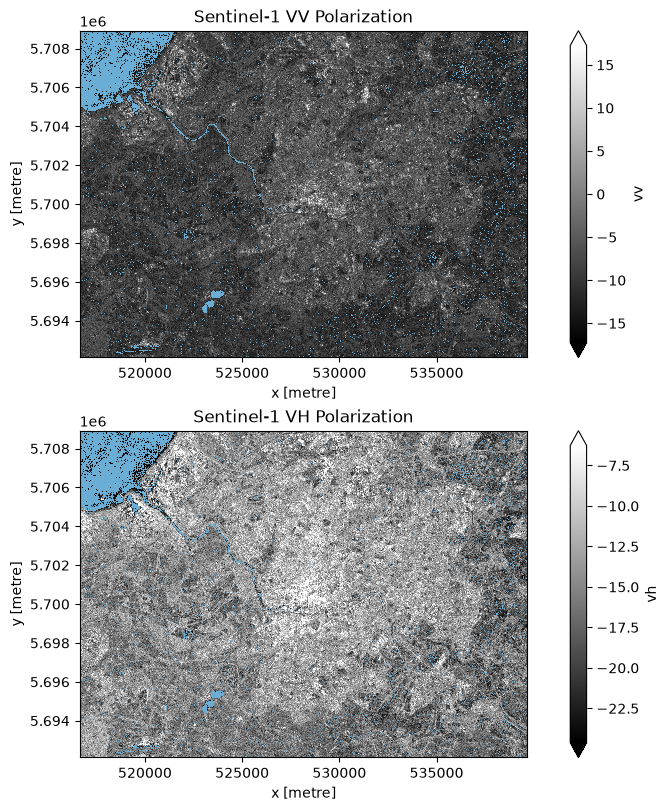

In [65]:
# Mask according to common thresholds
vh_water_mask = vh_log < -22  # threshold for water detection in dB scale
vv_water_mask = vv_log < -15  # threshold for water detection in dB scale

# mask 0 regions as NaN
vh_water_mask = vh_water_mask.where(vh_water_mask != 0)
vv_water_mask = vv_water_mask.where(vv_water_mask != 0)

fig, axes = plt.subplots(nrows=2, layout="constrained", figsize=(10, 8))

ax = axes[0]
vv_log.plot.imshow(ax=ax, cmap="gray", robust=True)
vv_water_mask.plot.imshow(ax=ax, cmap="Blues", vmin=0, vmax=2, add_colorbar=False)
ax.set_title("Sentinel-1 VV Polarization")
ax.set_aspect('equal')

ax = axes[1]
vh_log.plot.imshow(ax=ax, cmap="gray", robust=True)
vv_water_mask.plot.imshow(ax=ax, cmap="Blues", vmin=0, vmax=2, add_colorbar=False)
ax.set_title("Sentinel-1 VH Polarization")
ax.set_aspect('equal')

This has worked pretty well at capturing broad regions (river, lakes, the sea), but is not perfect. The main problem is that SAR data can be quite noisy (referred to as **speckle**), and some preprocessing in either the spatial (e.g. speckle filtering, such as Lee filtering) or temporal (e.g multi-temporal composites of many scenes) domain may help to reduce this. [Digital Earth Australia has an excellent worked example showing how you might approach this using the geospatial Python stack](https://knowledge.dea.ga.gov.au/notebooks/Real_world_examples/Radar_water_detection/). 

However, these methods involve a trade-off: reducing noise can also remove genuine small features and sharp boundaries. The appropriate method depends on the application, spatial resolution, and whether preserving fine-scale features is important. Alternatively, moving from on from pixel-based analysis (e.g. to object-based segmentation or convolutional neural nets) may be a solution for more complex problems.

## Further Learning Opportunities

 - [NASA Short Intro to SAR Data](https://www.earthdata.nasa.gov/learn/earth-observation-data-basics/sar).
 - [ESA Sentinel-1 Main Page](https://esthub.maaruum.ee/eng/help/esthub-data/sentinel-1-p89.html).
 - [NASA Introduction to Synthetic Aperture Radar and its Applications](https://www.earthdata.nasa.gov/learn/trainings/introduction-synthetic-aperture-radar-sar-its-applications) introductory course.
 - [NASA SAR Handbook](https://www.earthdata.nasa.gov/learn/earth-observation-data-basics/sar-handbook).
 - [Project Pythia: Microwave Remote Sensing.](https://projectpythia.org/eo-datascience-cookbook/notebooks/courses/microwave-remote-sensing/)
 - [Digital Earth Australia: Detecting Water in S-1 data using `xarray`](https://knowledge.dea.ga.gov.au/notebooks/Real_world_examples/Radar_water_detection/)
 - Alaska Satellite Facility (ASF):
   - [Introduction to SAR](https://hyp3-docs.asf.alaska.edu/guides/introduction_to_sar/).
   - [Introduction to the Sentinel-1 Mission](https://hyp3-docs.asf.alaska.edu/sentinel1/).
   - Using the ASF to download processed [RTC](https://hyp3-docs.asf.alaska.edu/guides/rtc_product_guide/) and [InSAR](https://hyp3-docs.asf.alaska.edu/guides/insar_product_guide/) data.
 - [Google Earth Engine SAR Tutorial](https://developers.google.com/earth-engine/tutorials/community/sar-basics).
 - Some ideas from the tutorials of the [ESA EOPF Zarr Toolkit](https://eopf-toolkit.github.io/eopf-101/index.html)
   - [Flood detection and mapping using change detection](https://eopf-toolkit.github.io/eopf-101/06_eopf_zarr_in_action/614_flood_change_detection_s1.html).
   - [Time-series analysis of surface water dynamics](https://eopf-toolkit.github.io/eopf-101/06_eopf_zarr_in_action/69_coastal_water_dynamics_s1.html).